# SWIFT window lab: bin coverage, width and shape

Start with **Whole-bank sensitivity** to sweep tones across the default 12-bin/octave domain,
varying detector width and imbalance d. Compare the aggregate response, the strongest detector,
and how one tone spreads across bins. The width/d maps expose the tradeoff between flatness,
selectivity and temporal age.

The later single-detector lab holds **S = ts + tf** fixed to isolate the remaining shape parameter.
The real-audio/STBR experiment remains an appendix. These are complementary experiments:
the bank controls width, while the single-detector section controls S.

Run all cells, then move the sliders. Ordinary saved plots remain readable without widgets.
NumPy, Matplotlib, ipywidgets and a Jupyter frontend are required. Controls update on release.
This is an **audio-independent analysis prototype**; production filters are not modified.


## Decide the scale first; then vary the shape

`f0` is the center frequency, `R` the domain resolution in bins per octave, and
`ts >= tf >= 0` the slow and fast time constants in seconds.

```text
f[k] = fmin * 2**(k/R)
S = ts + tf                  d = (ts-tf)/S
ts = S*(1+d)/2               tf = S*(1-d)/2
old fast/slow ratio = (1-d)/(1+d)
```

Constant Q requires bandwidth proportional to f0. With d held common across bins,
choose S proportional to 1/f0. Constant Q does not choose d.

This lab anchors S to a periodic Hann reference derived from the domain resolution:
`C = round(1/(2**(1/R)-1))` carrier cycles, `S = m*C/(3*f0)` seconds.
The scale multiplier m is a separate bandwidth decision. Hann duration is approximately
`3*S`, giving the same **two-sided equivalent noise bandwidth (ENBW)**, `1/(2*S)`.
Its integer sample length is chosen once per scale, independently of d.

**Fixed S means fixed ENBW and mean age in the continuous-time model.** It does not mean
fixed -3 dB width or fixed neighboring-bin rejection. Exact sampled values differ slightly;
the interactive plots and printed metrics use the exact discrete filter and expose that difference.
This fixed-S/Hann-ENBW experiment is a comparison convention, not the production calibration.
Production uses the whole-bank width definition below: width scale 1 and imbalance d = 0,
with exact sampled half-power calibration. Its settings expose width 0.25-8 and d from 0 to 1.

## What the remaining degree of freedom does

For continuous time t >= 0, the unit-area age envelope is:

```text
0 < d < 1: h(t) = (exp(-t/ts)-exp(-t/tf))/(ts-tf)
d = 0:     h(t) = 4*t/S**2 * exp(-2*t/S)
d = 1:     h(t) = exp(-t/S)/S

Mean age = S
Variance = ts**2 + tf**2 = S**2*(1+d**2)/2
Standard deviation = S*sqrt((1+d**2)/2)
Peak age = S*(1-d**2)/(4*d) * log((1+d)/(1-d))
           with limits S/2 at d=0 and 0 at d=1
```

Increasing d moves the peak toward the present and increases spread, with a longer old-sample
tail to preserve the mean. Spread is bounded: S/sqrt(2) <= standard deviation <= S.
These are coupled changes, not independent attack and release controls.

At frequency offset df from the center, let u = 2*pi*df*S:

```text
abs(H(df))**2 = 1 / [1 + u**2*(1+d**2)/2 + u**4*(1-d**2)**2/16]
```

Increasing d narrows the central peak but raises distant leakage. ENBW stays constant:
less transmission in the shoulders is balanced by more in the tails. For d < 1 the eventual
slope is -40 dB/decade; at d = 1 it is -20 dB/decade. Near 1, the second pole can be outside
the visible frequency range. All curves have unit coherent center gain.

**Default:** d = 0 is a baseline for minimum temporal spread and distant leakage, not a universal
optimum. Increase d if earlier onset response or a narrower core is more useful. The old guessed
ratio 0.6 maps to d = 0.25; it has no special constant-Q status.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as W
from IPython.display import display, clear_output

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": .22, "axes.spines.top": False,
                     "axes.spines.right": False})
COLORS = {"slow": "#3178c6", "fast": "#df8b24", "alpha": "#209779", "hann": "#9656ad"}

def poles(fs, ts, tf):
    def one(t):
        if t == 0:
            return 0., 1.
        v = -1/(fs*t)
        return np.exp(v), -np.expm1(v)
    a, ca = one(ts)
    b, cb = one(tf)
    return a, b, ca, cb

def responses(d, fs, ts, tf):
    """Exact discrete-time responses at offset d from the resonator frequency."""
    a, b, ca, cb = poles(fs, ts, tf)
    v = np.expm1(-2j*np.pi*np.asarray(d)/fs)
    hs = ca / (ca-a*v)
    hf = cb / (cb-b*v)
    return hs, hf, (1+v)*hs*hf

def dirichlet(d, fs, n):
    """sum(exp(-i*2*pi*d*k/fs), k=0..n-1), including removable singularities."""
    u = (np.asarray(d)/fs + .5) % 1 - .5
    return n*np.exp(-1j*np.pi*(n-1)*u)*np.sinc(n*u)/np.sinc(u)

def hann_response(d, fs, n):
    # Periodic causal Hann: w[k] = .5 - .5*cos(2*pi*k/n), k=0..n-1.
    # Coherent gain is n/2; this is not the symmetric (n-1 denominator) variant.
    return (dirichlet(d, fs, n) - .5*dirichlet(np.asarray(d)-fs/n, fs, n)
            - .5*dirichlet(np.asarray(d)+fs/n, fs, n))/n

def half_width(response, fs):
    lo, hi = 0., fs/2
    for _ in range(55):
        mid = (lo+hi)/2
        if abs(response(mid)) > np.sqrt(.5): lo = mid
        else: hi = mid
    return (lo+hi)/2

def windows(k, fs, ts, tf):
    """Raw individual/difference windows, plus their unit-sum versions."""
    k = np.asarray(k, dtype=float)
    a, b, ca, cb = poles(fs, ts, tf)
    if ts == 0 or tf == 0:
        ws, wf = np.power(a, k), np.power(b, k)
        pole, gain = (b, cb) if ts == 0 else (a, ca)
        combined = np.where(k >= 1, gain*np.power(pole, np.maximum(k-1, 0)), 0.)
        return ws, wf, ws-wf, ca*ws, cb*wf, combined
    ls, lf = -1/(fs*ts), -1/(fs*tf)
    ws, wf = np.exp(k*ls), np.exp(k*lf)
    # Stable divided difference: (a^k-b^k)/(a-b), multiplied by ca*cb.
    hi, lo = max(ls, lf), min(ls, lf)
    delta = lo-hi
    if delta == 0:
        combined = ca*cb*k*np.exp(np.maximum(k-1, 0)*hi)
    else:
        combined = ca*cb*np.exp(np.maximum(k-1, 0)*hi)*np.expm1(k*delta)/np.expm1(delta)
    return ws, wf, ws-wf, ca*ws, cb*wf, combined

def db(z): return 20*np.log10(np.maximum(np.abs(z), 1e-8))

def stats(fs, ts, tf, n):
    a, b, ca, cb = poles(fs, ts, tf)
    width = half_width(lambda d: responses(d, fs, ts, tf)[2], fs)
    return {"alpha_half_hz": width,
            "hann_half_hz": half_width(lambda d: hann_response(d, fs, n), fs),
            "alpha_age_ms": 1000*(1+a/ca+b/cb)/fs,
            "hann_age_ms": 1000*n/(2*fs)}

In [2]:
def split(S, d):
    if S <= 0 or not 0 <= d <= 1:
        raise ValueError('Require S > 0 and 0 <= d <= 1')
    return S*(1+d)/2, S*(1-d)/2

def scale(f0, bins, multiplier=1.):
    cycles = round(1/np.expm1(np.log(2)/bins))
    return multiplier*cycles/(3*f0)

def sampled_metrics(fs, ts, tf):
    a, b, ca, cb = poles(fs, ts, tf)
    mean = (1+a/ca+b/cb)/fs  # includes the explicit output delay
    sigma = np.sqrt(a/ca**2+b/cb**2)/fs
    enbw = fs*ca*cb*(1+a*b)/((1+a)*(1+b)*(ca+a*cb))
    width = 2*half_width(lambda df: responses(df, fs, ts, tf)[2], fs)
    return mean, sigma, enbw, width

def continuous_shape(d):
    if d == 0:
        peak = .5
    elif d == 1:
        peak = 0.
    else:
        peak = (1-d*d)/(4*d)*np.log1p(2*d/(1-d))
    # Full -3 dB width times S, solved without cancellation.
    c2, c4 = (1+d*d)/2, (1-d*d)**2/16
    width = np.sqrt(2/(c2+np.sqrt(c2*c2+4*c4)))/np.pi
    return peak, np.sqrt((1+d*d)/2), width

## Whole-bank sensitivity: width and imbalance

This experiment uses the **actual default domain**: 30 Hz to 8000 Hz, R = 12 bins/octave,
97 centers from 30 Hz to 7680 Hz, at fs = 48000 Hz. Centers follow `30*2**(k/12)`;
the count follows production's `round(R*log2(max/min))`. This is a finite bank, not an
assumed infinite periodic tiling. Responses are analytic; no FFT or time simulation is used.

The two controls here are **width w** and **imbalance d**:

```text
geometric bin edges = center * 2**(+/-1/(2*R))
bin_width = upper_edge - lower_edge
w = full -3 dB detector width / bin_width
```

At w = 1 the -3 dB width equals the bin width. The response is symmetric in linear Hz,
while log-bin edges are slightly asymmetric, so this does not put both edges at exactly -3 dB.
For each bin we solve the **exact sampled response** for S, given w and d. Moving d here
therefore retunes S to preserve width. The later single-detector lab instead holds S fixed.
Production now uses this same width/imbalance calibration, defaulting to w = 1 and d = 0.
It solves for S by construction-time bisection for every d, including equal stages.
This section does not use Hann to calibrate SWIFT. Production Hann is an independent reference.

We sweep a unit-amplitude **complex tone** through the centers and boundaries. Each filter
has unit gain at its center. The reported aggregate curves have distinct meanings:

```text
G[k,f] = abs(H[k](f))
P(f) = sum_k G[k,f]**2       summed detector power
A(f) = sum_k G[k,f]          summed magnitudes (related to the current magnitude patch mean)
M(f) = max_k G[k,f]          strongest-detector amplitude
```

P is not a conserved input power: overlapping detectors count a tone more than once.
A is not power and is not the magnitude of a coherent sum. M measures scalloping of the
best individual observation. The local ripple panel removes one constant gain per curve
to expose variation; the whole-domain panel and printed totals retain the absolute gain.

In [3]:
BANK_FS, BANK_R = 48000, 12
BANK_MIN, BANK_MAX = 30., 8000.
BANK_COUNT = round(BANK_R*np.log2(BANK_MAX/BANK_MIN))
BANK_CENTERS = BANK_MIN*2**(np.arange(BANK_COUNT)/BANK_R)
BANK_WIDTHS = BANK_CENTERS*(2**(.5/BANK_R)-2**(-.5/BANK_R))
BANK_ANCHOR = BANK_COUNT//2  # actual center: 480 Hz
BANK_F0 = BANK_CENTERS[BANK_ANCHOR]

def bank_decay(times, fs=BANK_FS):
    times = np.asarray(times, dtype=float)
    exponent = -np.divide(1., fs*times, out=np.full_like(times, np.inf), where=times > 0)
    return np.exp(exponent), -np.expm1(exponent)

def tune_bank(width, d, centers=BANK_CENTERS, fs=BANK_FS, bins=BANK_R):
    """Solve |H(center +/- target_width/2)|^2 = 1/2 for every bin."""
    if width <= 0 or not 0 <= d <= 1:
        raise ValueError('Require width > 0 and 0 <= d <= 1')
    centers = np.asarray(centers, dtype=float)
    target_width = width*centers*(2**(.5/bins)-2**(-.5/bins))
    if np.any(target_width >= fs):
        raise ValueError('Target width must fit in one sampled frequency period')
    sine = 4*np.sin(np.pi*target_width/(2*fs))**2
    def edge_power(S):
        a, ca = bank_decay(S*(1+d)/2, fs)
        b, cb = bank_decay(S*(1-d)/2, fs)
        return ca**2/(ca**2+a*sine) * cb**2/(cb**2+b*sine)
    lo = np.zeros_like(centers)
    hi = 8/centers
    while np.any(edge_power(hi) > .5):
        hi = np.where(edge_power(hi) > .5, hi*2, hi)
    for _ in range(48):
        mid = (lo+hi)/2
        longer = edge_power(mid) > .5
        lo, hi = np.where(longer, mid, lo), np.where(longer, hi, mid)
    S = (lo+hi)/2
    a, ca = bank_decay(S*(1+d)/2, fs)
    b, cb = bank_decay(S*(1-d)/2, fs)
    return dict(S=S, a=a, ca=ca, b=b, cb=cb,
                centers=centers, fs=fs, target_width=target_width)

def bank_sine(tones, centers=BANK_CENTERS, fs=BANK_FS):
    return 4*np.sin(np.pi*(np.asarray(tones)[:, None]-centers[None, :])/fs)**2

def bank_power_from_sine(sine, bank):
    a, ca, b, cb = (bank[k][None, :] for k in ['a', 'ca', 'b', 'cb'])
    return ca**2/(ca**2+a*sine) * cb**2/(cb**2+b*sine)

def bank_power(tones, bank):
    return bank_power_from_sine(bank_sine(tones, bank['centers'], bank['fs']), bank)

def bank_summary(power):
    gain = np.sqrt(power)
    return power.sum(axis=1), gain.sum(axis=1), gain.max(axis=1)

def power_db(power):
    return 10*np.log10(np.maximum(power, 1e-20))

def relative_curve(value, power=False):
    # One scalar normalization over uniformly spaced log-frequency samples.
    return (10 if power else 20)*np.log10(np.maximum(value, 1e-20)/np.mean(value))

def ripple(value, power=False):
    return float((10 if power else 20)*np.log10(np.max(value)/np.min(value)))

def hann_bank_power(tones, centers=BANK_CENTERS, fs=BANK_FS, bins=BANK_R):
    """Actual production periodic Hann: rounded length and resulting center detuning."""
    cycles = round(1/np.expm1(np.log(2)/bins))
    lengths = np.rint(cycles*fs/centers).astype(int)
    actual = cycles*fs/lengths
    return np.column_stack([np.abs(hann_response(np.asarray(tones)-f, fs, int(n)))**2
                            for f, n in zip(actual, lengths)])

def bank_mean_age(bank, index=BANK_ANCHOR):
    return (1+bank['a'][index]/bank['ca'][index]
             +bank['b'][index]/bank['cb'][index])/bank['fs']

def bank_temporal(width, d):
    # A 60 Hz bin is in the actual domain and makes the bass latency visible.
    j = BANK_R
    cases = [(w, f'w = {w:g}', 'gray', style) for w, style in [(.5, '--'), (1., '-.'), (2., ':')]
             if not np.isclose(w, width)]
    cases.append((width, f'Selected w = {width:.3f}, d = {d:.2f}', COLORS['alpha'], '-'))
    banks = [tune_bank(w, d) for w, *_ in cases]
    end = int(np.ceil(8*max(bank['S'][j] for bank in banks)*BANK_FS))+1
    k = np.arange(end)
    take = np.unique(np.r_[np.arange(min(128, end)), np.linspace(0, end-1, 4000).astype(int)])
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), constrained_layout=True)
    view_ms = 0.
    for (_, label, color, style), bank in zip(cases, banks):
        ts, tf = split(bank['S'][j], d)
        step = np.cumsum(windows(k, BANK_FS, ts, tf)[-1])
        view_ms = max(view_ms, 1000*np.searchsorted(step, .95)/BANK_FS)
        axes[0].plot(k[take]/BANK_FS*1000, step[take], color=color, ls=style, label=label)
        axes[1].plot(k[take]/BANK_FS*1000, np.maximum(0, 1-step[take]), color=color, ls=style, label=label)
    n = round(17*BANK_FS/BANK_CENTERS[j])
    hann = np.where(k < n, .5-.5*np.cos(2*np.pi*k/n), 0)/(n/2)
    hann_step = np.cumsum(hann)
    axes[0].plot(k[take]/BANK_FS*1000, hann_step[take], color=COLORS['hann'], ls=':', label='Production Hann')
    axes[1].plot(k[take]/BANK_FS*1000, np.maximum(0, 1-hann_step[take]), color=COLORS['hann'], ls=':')
    for ax, title in zip(axes, ['Bass-bin coherent onset', 'Bass-bin release from steady state']):
        ax.set(title=title, xlabel='Time (ms), tone at 60 Hz', ylabel='Fraction of settled amplitude',
               ylim=(0, 1.03), xlim=(0, 1.08*max(view_ms, 1000*n/BANK_FS)))
        ax.axhline(.1, color='gray', lw=.7, ls=':')
        ax.axhline(.9, color='gray', lw=.7, ls=':')
    axes[0].legend(fontsize=8)
    fig.suptitle('Temporal cost at 60 Hz: d fixed, width varied; 30 Hz is about twice as slow')
    plt.show()
    plt.close(fig)

def bank_lab(width=1., d=0., show_hann=True):
    bank = tune_bank(width, d)
    x = np.linspace(0, 1, 401)  # includes both centers and their geometric midpoint
    tones = BANK_F0*2**(x/BANK_R)
    power = bank_power(tones, bank)
    P, A, M = bank_summary(power)
    broad_x = np.linspace(-1, 2, 901)
    broad_tones = BANK_F0*2**(broad_x/BANK_R)
    broad_power = bank_power(broad_tones, bank)
    broad_P = broad_power.sum(axis=1)
    full_tones = np.geomspace(BANK_MIN/1.7, min(BANK_MAX*1.5, BANK_FS*.49), 2001)
    full_power = bank_power(full_tones, bank)
    full_P = full_power.sum(axis=1)
    # For a real cosine, time-mean (2*abs(z))^2 includes both frequency images.
    real_P = full_P + bank_power(-full_tones, bank).sum(axis=1)
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
    for j in range(BANK_ANCHOR-3, BANK_ANCHOR+5):
        axes[0, 0].plot(broad_x, power_db(broad_power[:, j]), lw=1,
                        label=f'Bin {j-BANK_ANCHOR:+d}')
    axes[0, 0].plot(broad_x, power_db(broad_P), color='black', lw=2, label='Sum of all 97 powers')
    for edge in [-.5, .5, 1.5]:
        axes[0, 0].axvline(edge, color='gray', lw=.7, ls=':')
    axes[0, 0].axhline(-3.0103, color='gray', lw=.7, ls=':')
    axes[0, 0].set(title='Individual detectors and absolute aggregate', xlabel='Semitones from 480 Hz',
                    ylabel='Power / unit input (dB)', ylim=(-35, max(5, float(power_db(broad_P).max())+1)))
    axes[0, 0].legend(ncol=3, fontsize=7)
    for values, is_power, color, label in [(P, True, 'black', 'Summed power'),
                                          (A, False, COLORS['fast'], 'Summed magnitudes'),
                                          (M, False, COLORS['alpha'], 'Strongest detector')]:
        axes[0, 1].plot(x, relative_curve(values, is_power), color=color,
                        label=f'{label}: {ripple(values, is_power):.3f} dB p-p')
    if show_hann:
        hp = hann_bank_power(tones)
        axes[0, 1].plot(x, relative_curve(hp.sum(axis=1), True), color=COLORS['hann'], ls='--',
                        label=f'Hann summed power: {ripple(hp.sum(axis=1), True):.3f} dB p-p')
    axes[0, 1].axvline(.5, color='gray', lw=.7, ls=':')
    axes[0, 1].set(title='Center to center: sensitivity ripple after one gain normalization',
                    xlabel='Semitones from 480 Hz', ylabel='Response / mean response (dB)')
    axes[0, 1].legend(fontsize=8)
    axes[1, 0].semilogx(full_tones, power_db(full_P), color='black', label='Complex tone: summed power')
    axes[1, 0].semilogx(full_tones, power_db(real_P), color=COLORS['fast'], ls=':',
                       label='Real cosine: time-mean summed power, including image')
    if show_hann:
        axes[1, 0].semilogx(full_tones, power_db(hann_bank_power(full_tones).sum(axis=1)),
                           color=COLORS['hann'], ls='--', label='Production Hann: complex-tone power')
    axes[1, 0].axvspan(full_tones[0], BANK_MIN*2, color='gray', alpha=.10)
    axes[1, 0].axvspan(BANK_CENTERS[-1]/2, full_tones[-1], color='gray', alpha=.10)
    for edge in [BANK_MIN, BANK_CENTERS[-1]]:
        axes[1, 0].axvline(edge, color='gray', lw=.8, ls=':')
    axes[1, 0].set(title='Finite domain: local ripple, broad drift and missing edge neighbors',
                    xlabel='Tone frequency (Hz; gray = outside the interior scoring region)',
                    ylabel='Absolute summed power / unit input (dB)')
    axes[1, 0].legend(fontsize=7)
    selected = np.arange(BANK_ANCHOR-3, BANK_ANCHOR+5)
    positions = np.arange(len(selected)+1)
    for row, shift, color, label in [(0, -.18, COLORS['slow'], 'Tone at bin center'),
                                     (200, .18, COLORS['fast'], 'Tone at shared boundary')]:
        shares = power[row, selected]/P[row]
        fractions = np.r_[shares, max(0., 1-shares.sum())]
        axes[1, 1].bar(positions+shift, 100*fractions, width=.35, color=color, label=label)
    axes[1, 1].set_xticks(positions, [f'{j-BANK_ANCHOR:+d}' for j in selected]+['Others'])
    axes[1, 1].set(title='Selectivity cost: distribution over overlapping outputs',
                    xlabel='Detector offset in semitones', ylabel='Share of summed detector power (%)')
    axes[1, 1].legend(fontsize=8)
    fig.suptitle(f'97-bin default domain | -3 dB width / bin width = {width:.3f} | d = {d:.2f}')
    plt.show()
    plt.close(fig)
    interior = (full_tones >= 2*BANK_MIN) & (full_tones <= BANK_CENTERS[-1]/2)
    print(f'At 480 Hz: full -3 dB width = {bank["target_width"][BANK_ANCHOR]:.3f} Hz; '
          f'S = {bank["S"][BANK_ANCHOR]*1000:.3f} ms; exact mean age = {1000*bank_mean_age(bank):.3f} ms')
    print(f'Local summed power: mean {P.mean():.5f} ({float(power_db(P.mean())):+.3f} dB), '
          f'ripple {ripple(P, True):.5f} dB; interior 60-3840 Hz range {ripple(full_P[interior], True):.4f} dB')
    print(f'Strongest detector at midpoint: {20*np.log10(M[200]):.3f} dB; '
          f'largest center-tone power share: {100*power[0].max()/P[0]:.2f}%')
    print('Broader filters can flatten the aggregate by making more bins respond to the same tone.')
    bank_temporal(width, d)

bank_controls = {
    'width': W.FloatLogSlider(value=1., base=2, min=-2, max=3, step=.05,
                             description='Width w', readout_format='.3f', continuous_update=False),
    'd': W.FloatSlider(value=0., min=0, max=1, step=.01, description='Imbalance d', continuous_update=False),
    'show_hann': W.Checkbox(value=True, description='Show production Hann reference'),
}
bank_output = W.interactive_output(bank_lab, bank_controls)
display(W.VBox([bank_controls['width'], bank_controls['d'], bank_controls['show_hann']]), bank_output)

Output()

### Is there one flattest setting?

There is an optimum only after defining **what is aggregated**, which frequency region is scored,
what gain normalization is allowed, and which selectivity/latency constraints must hold.
The following maps sweep both width and d using the exact finite-bank responses.

- **Local ripple:** peak-to-peak variation in summed power between adjacent interior centers,
  480 Hz to 508.54 Hz. It measures position sensitivity near one pitch.
- **Interior range:** peak-to-peak summed-power variation across 60-3840 Hz, excluding one octave
  at each bank end. It includes both local scalloping and broad frequency drift. The full-domain
  plot above shows the excluded edges explicitly.
- **Center-tone concentration:** fraction of summed output power in the strongest detector for a
  tone exactly at 480 Hz. High concentration means more selective labeling, not greater input power.
- **Mean age:** exact sampled age at 480 Hz; shows the temporal cost of a setting.

All filters keep unit center gain. Flatness metrics remove a constant gain implicitly through
max/min; concentration and the printed absolute totals reveal the overlap hidden by that metric.
The heatmaps have different color scales and units; a low ripple is not an overall quality score.
The reference crosses mark w = 1, d = 0, not a claimed optimum.

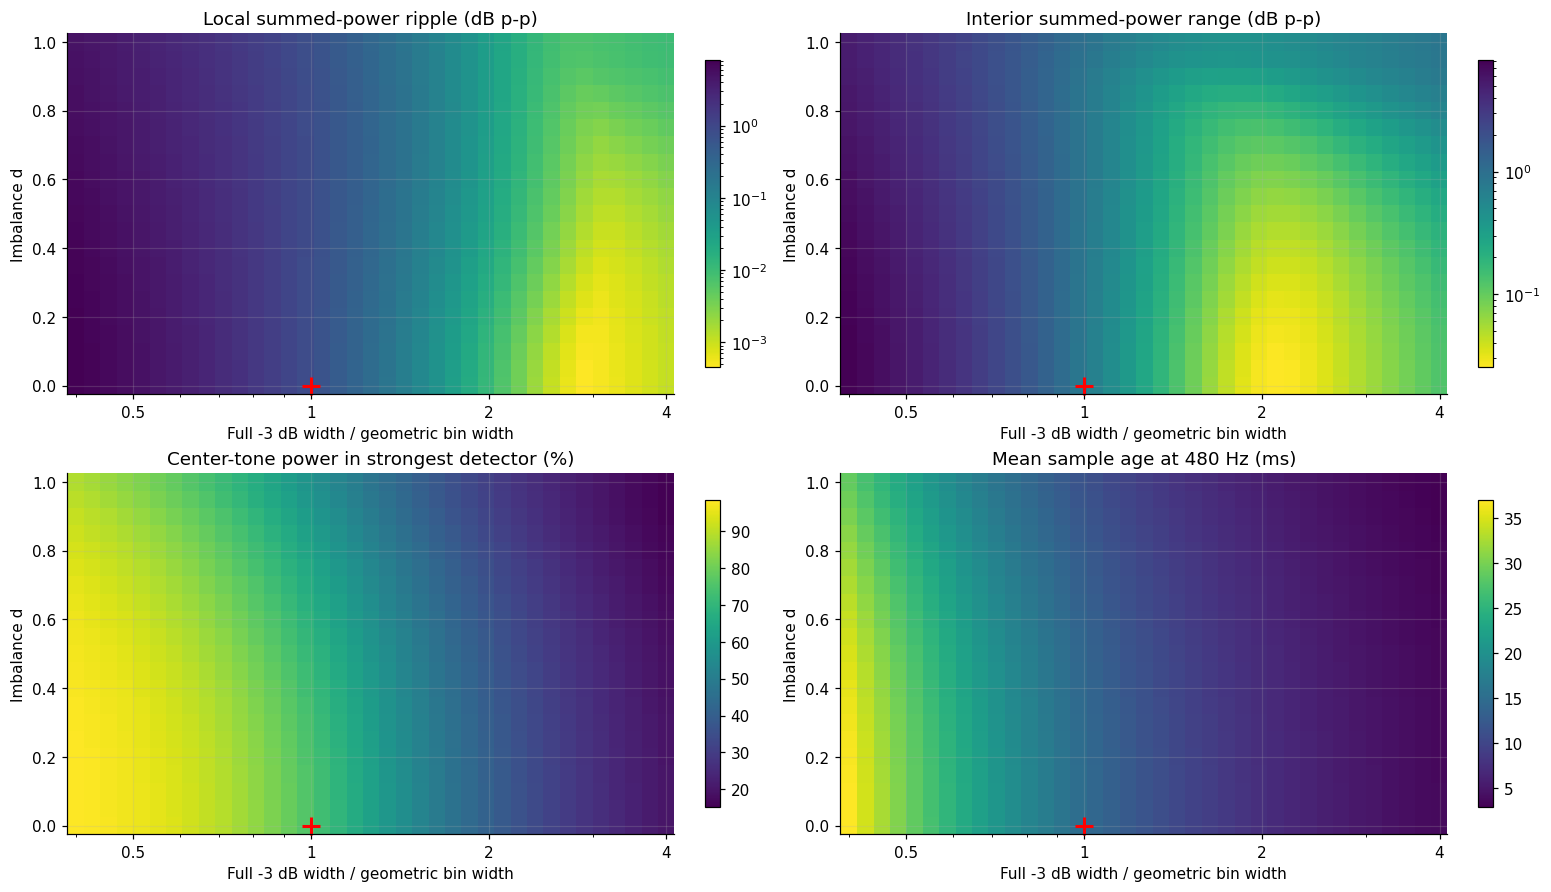

Sampled grid minima within w=0.4..4, d=0..1; these are not unconstrained optima:
Objective                  width      d   local dB   interior dB   center share   mean age ms   mean power
Lowest local ripple         2.905   0.00    0.00045       0.05015         27.72%         5.086       3.6070
Lowest interior range       2.110   0.00    0.00676       0.02549         38.45%         7.003       2.5988
Denser frequency sampling, Local summed-power ripple (dB p-p): 0.000451
Denser frequency sampling, Interior summed-power range (dB p-p): 0.025518


In [4]:
def coverage_maps():
    widths = np.geomspace(.4, 4., 37)
    ds = np.linspace(0, 1, 21)
    local_tones = BANK_F0*2**(np.linspace(0, 1, 193)/BANK_R)
    # 24 observations per semitone across six interior octaves, including bin centers/boundaries.
    interior_tones = BANK_MIN*2*2**(np.arange(72*24+1)/(24*BANK_R))
    local_sine, interior_sine = bank_sine(local_tones), bank_sine(interior_tones)
    metrics = np.empty((len(ds), len(widths), 4))
    totals = np.empty((len(ds), len(widths)))
    for row, d in enumerate(ds):
        for col, width in enumerate(widths):
            bank = tune_bank(width, d)
            local = bank_power_from_sine(local_sine, bank)
            P = local.sum(axis=1)
            interior = bank_power_from_sine(interior_sine, bank).sum(axis=1)
            metrics[row, col] = [ripple(P, True), ripple(interior, True),
                                 100*local[0].max()/P[0], 1000*bank_mean_age(bank)]
            totals[row, col] = P.mean()
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
    titles = ['Local summed-power ripple (dB p-p)', 'Interior summed-power range (dB p-p)',
              'Center-tone power in strongest detector (%)', 'Mean sample age at 480 Hz (ms)']
    for j, ax in enumerate(axes.flat):
        data = metrics[:, :, j]
        # Log color exposes tiny residual ripple without calling it exactly zero.
        if j < 2:
            from matplotlib.colors import LogNorm
            norm = LogNorm(vmin=max(1e-5, float(data.min())), vmax=float(data.max()))
            cmap = 'viridis_r'
        else:
            norm, cmap = None, 'viridis'
        im = ax.pcolormesh(widths, ds, data, shading='nearest', norm=norm, cmap=cmap)
        ax.set_xscale('log')
        ax.set_xticks([.5, 1., 2., 4.], ['0.5', '1', '2', '4'])
        ax.plot([1], [0], marker='+', color='red', ms=12, mew=2, clip_on=False)
        ax.set(title=titles[j], xlabel='Full -3 dB width / geometric bin width', ylabel='Imbalance d')
        fig.colorbar(im, ax=ax, shrink=.85)
    plt.show()
    plt.close(fig)
    print('Sampled grid minima within w=0.4..4, d=0..1; these are not unconstrained optima:')
    print('Objective                  width      d   local dB   interior dB   center share   mean age ms   mean power')
    for j, label in [(0, 'Lowest local ripple'), (1, 'Lowest interior range')]:
        row, col = np.unravel_index(np.argmin(metrics[:, :, j]), metrics[:, :, j].shape)
        a, b, c, age = metrics[row, col]
        print(f'{label:25s} {widths[col]:7.3f} {ds[row]:6.2f} {a:10.5f} {b:13.5f} '
              f'{c:13.2f}% {age:13.3f} {totals[row, col]:12.4f}')
    # Reevaluate each reported grid minimum on a denser independent frequency grid.
    for j in [0, 1]:
        row, col = np.unravel_index(np.argmin(metrics[:, :, j]), metrics[:, :, j].shape)
        bank = tune_bank(widths[col], ds[row])
        dense = (BANK_F0*2**(np.linspace(0, 1, 769)/BANK_R) if j == 0 else
                 BANK_MIN*2*2**(np.arange(72*96+1)/(96*BANK_R)))
        refined = ripple(bank_power(dense, bank).sum(axis=1), True)
        print(f'Denser frequency sampling, {titles[j]}: {refined:.6f}')
    return widths, ds, metrics, totals

bank_map_results = coverage_maps()

### See the time-frequency tradeoff directly

**Slow filters do not flatten the steady-state bank.** Increasing duration narrows each detector,
concentrates a center tone in fewer bins, and tends to deepen the trough between centers.
Broad, fast filters overlap more, which can reduce aggregate ripple but weakens pitch selectivity.
At fixed width, changing d trades response shape and tail leakage against the required duration;
the plotted results determine which combinations are useful.

Each curve below fixes d and varies width. Left: aggregate flatness versus temporal age.
Right: pitch concentration versus temporal age. The labels show width; compare the same point
between panels. Low ripple without sufficient concentration is an unselective bank, not improved
spectral resolution. Likewise, slow temporal averaging of the already computed magnitude spectrum
would smooth fluctuations over time but would not fix a steady tone's between-bin sensitivity.

Mean age is a measure of temporal memory, not a hard delay or the time to settle. The live bank
plot also shows actual coherent onset and release curves at a 60 Hz bass bin. Constant-Q timing
scales approximately as 1/f: the same setting at 30 Hz takes about 16 times as long as at 480 Hz.

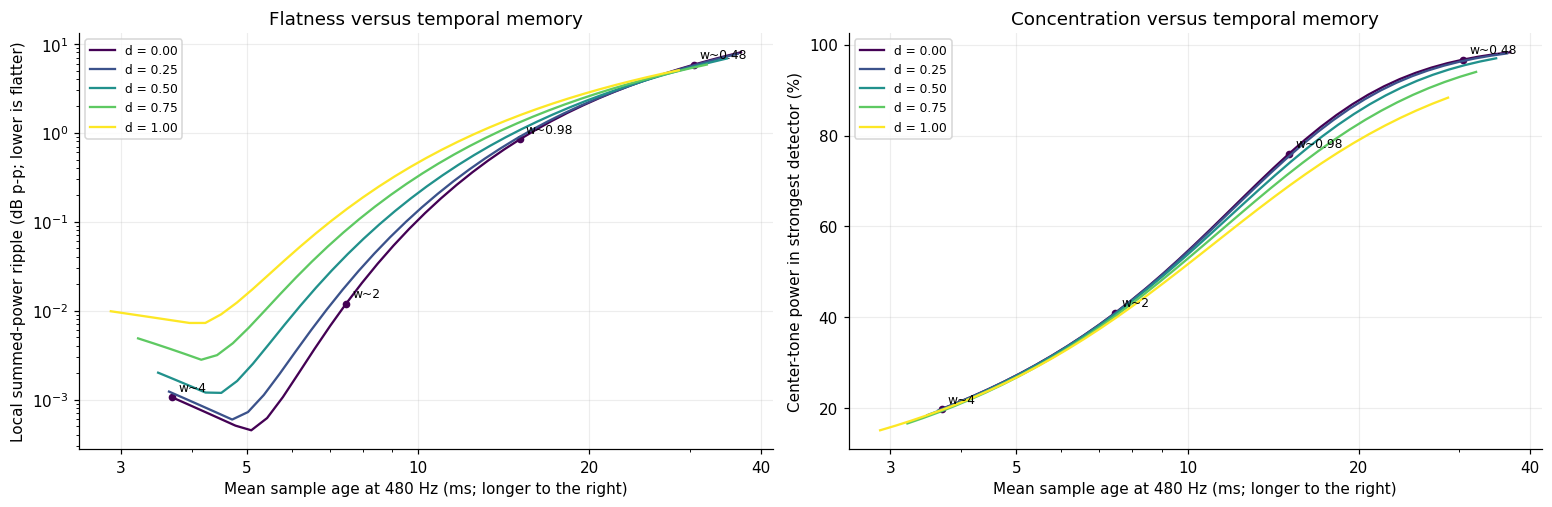

Illustrative settings; complex steady tone, all 97 detectors:
width    d    age at 480/30 Hz ms    local ripple dB    center share    strongest at boundary dB
 0.50  0.00     29.551/ 472.821            5.49016          96.32%                    -8.331
 1.00  0.00     14.776/ 236.410            0.77542          74.99%                    -2.937
 2.00  0.00      7.388/ 118.205            0.01093          40.58%                    -0.832
 4.00  0.00      3.694/  59.103            0.00106          19.84%                    -0.216
 1.00  0.50     13.952/ 223.229            0.82840          70.22%                    -2.943
 1.00  1.00     11.489/ 183.675            0.74150          57.59%                    -2.948


In [5]:
def bank_tradeoffs():
    widths, ds, metrics, totals = bank_map_results
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
    for target, color in zip([0., .25, .5, .75, 1.], plt.cm.viridis(np.linspace(0, 1, 5))):
        row = int(np.argmin(abs(ds-target)))
        age = metrics[row, :, 3]
        axes[0].plot(age, metrics[row, :, 0], color=color, label=f'd = {ds[row]:.2f}')
        axes[1].plot(age, metrics[row, :, 2], color=color, label=f'd = {ds[row]:.2f}')
        if target == 0:
            for w in [.5, 1., 2., 4.]:
                col = int(np.argmin(abs(widths-w)))
                for ax, metric in [(axes[0], 0), (axes[1], 2)]:
                    ax.plot(age[col], metrics[row, col, metric], 'o', color=color, ms=4)
                    ax.annotate(f'w~{widths[col]:.2g}', (age[col], metrics[row, col, metric]),
                                xytext=(4, 4), textcoords='offset points', fontsize=8)
    for ax in axes:
        ax.set_xscale('log')
        ax.set_xticks([3, 5, 10, 20, 40], ['3', '5', '10', '20', '40'])
        ax.set_xlabel('Mean sample age at 480 Hz (ms; longer to the right)')
        ax.legend(fontsize=8)
    axes[0].set_yscale('log')
    axes[0].set(title='Flatness versus temporal memory', ylabel='Local summed-power ripple (dB p-p; lower is flatter)')
    axes[1].set(title='Concentration versus temporal memory', ylabel='Center-tone power in strongest detector (%)')
    plt.show()
    plt.close(fig)
    print('Illustrative settings; complex steady tone, all 97 detectors:')
    print('width    d    age at 480/30 Hz ms    local ripple dB    center share    strongest at boundary dB')
    tones = BANK_F0*2**(np.linspace(0, 1, 401)/BANK_R)
    for width, d in [(.5, 0.), (1., 0.), (2., 0.), (4., 0.), (1., .5), (1., 1.)]:
        bank = tune_bank(width, d)
        power = bank_power(tones, bank)
        P, _, M = bank_summary(power)
        age = 1000*bank_mean_age(bank)
        bass_age = 1000*bank_mean_age(bank, 0)
        print(f'{width:5.2f} {d:5.2f} {age:10.3f}/{bass_age:8.3f} {ripple(P, True):18.5f} '
              f'{100*power[0].max()/P[0]:14.2f}% {20*np.log10(M[200]):25.3f}')

bank_tradeoffs()

### Why flatness alone is insufficient

The finite bank has a simple degenerate flat limit. As all time constants tend to zero,
every filter becomes a delayed identity with unit magnitude at every frequency:

```text
P(f) -> 97             A(f) -> 97             M(f) -> 1
Ripple -> 0            Strongest-bin power share -> 1/97
```

That is perfectly flat and has lost all pitch selectivity. It is outside the finite width slider's
range: once a filter never falls below half power, a -3 dB width is no longer defined.
Even before that limit, broadening can buy flatness by spreading one tone across many bins.
Different objectives can prefer different settings, and missing end channels can dominate a
literal whole-domain score. A local minimum on a bounded grid is not a universal best detector.

A useful design process is to choose the required **frequency discrimination or concentration**
and allowable **temporal age**, then inspect ripple among the settings satisfying those requirements.
For example, constrain neighboring-tone leakage or center-tone concentration, and show the resulting
worst between-center sensitivity. Do not normalize every tone frequency separately: that would
erase the very sensitivity variation being evaluated.

The real-tone dashed curve uses time-mean squared magnitudes and includes the negative-frequency
image. It is not an instantaneous phase-independent envelope. The heatmaps use complex tones to
isolate the intended passbands; real-image leakage can change practical rankings, especially for
broad filters and d near 1. A single-tone flat bank also does not imply an unbiased multi-tone
magnitude decomposition: overlapping complex tones can interfere before magnitude is taken.

### Saved whole-bank snapshot

The ordinary output below preserves the default w = 1, d = 0 comparison without widgets.
Use the Width w and Imbalance d sliders above to explore other settings.

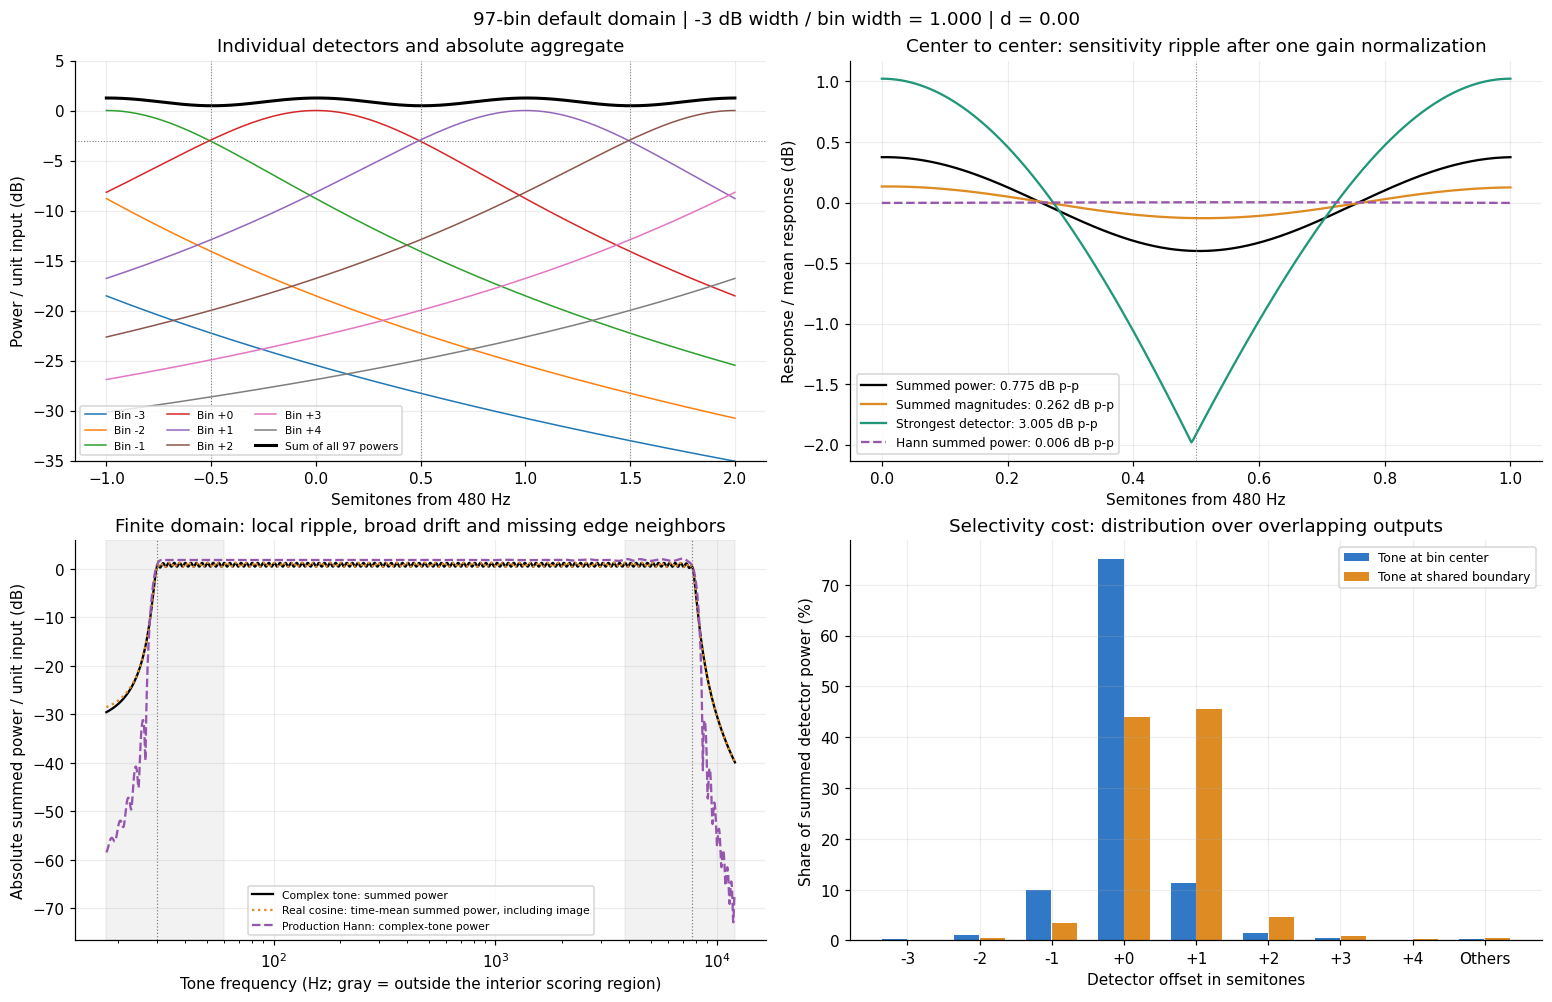

At 480 Hz: full -3 dB width = 27.730 Hz; S = 14.776 ms; exact mean age = 14.776 ms
Local summed power: mean 1.22328 (+0.875 dB), ripple 0.77542 dB; interior 60-3840 Hz range 0.7768 dB
Strongest detector at midpoint: -2.937 dB; largest center-tone power share: 74.99%
Broader filters can flatten the aggregate by making more bins respond to the same tone.


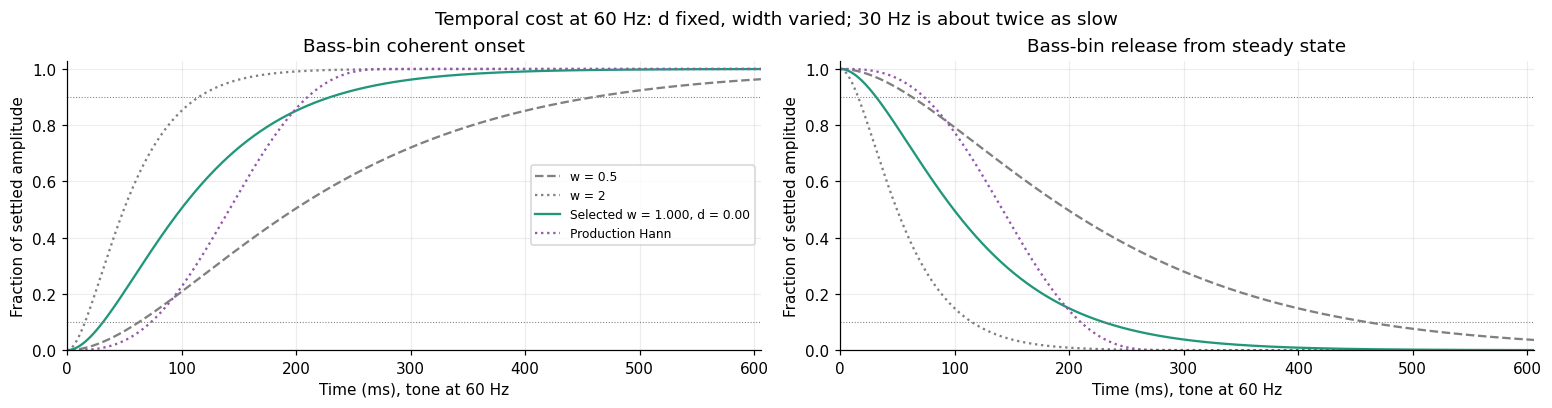

In [6]:
bank_lab()

### Bank response checks

Verify the solved half-power edges against the independent complex response helper, the zero-fast
endpoint, aggregate definitions, Hann center gain, and the flat all-pass limit. These are analytic
response checks, not rendering or processing performance measurements.

In [7]:
def verify_bank():
    for d in [0., .25, .9, 1.]:
        for width in [.25, 1., 4., 8.]:
            bank = tune_bank(width, d)
            for j in [0, BANK_ANCHOR, BANK_COUNT-1]:
                S = bank['S'][j]
                ts, tf = split(S, d)
                edge = bank['target_width'][j]/2
                np.testing.assert_allclose(abs(responses(edge, BANK_FS, ts, tf)[2])**2, .5, atol=2e-12)
                tones = bank['centers'][j]+np.array([0., edge, -edge, 2*edge])
                expected = np.abs(responses(tones-bank['centers'][j], BANK_FS, ts, tf)[2])**2
                np.testing.assert_allclose(bank_power(tones, bank)[:, j], expected, atol=2e-12)
    bank = tune_bank(1., 0.)
    sample = bank_power(np.array([BANK_F0, BANK_F0*2**(.5/BANK_R)]), bank)
    P, A, M = bank_summary(sample)
    np.testing.assert_allclose(P, np.sum(sample, axis=1))
    np.testing.assert_allclose(A, np.sum(np.sqrt(sample), axis=1))
    np.testing.assert_allclose(M, np.sqrt(np.max(sample, axis=1)))
    n = round(17*BANK_FS/BANK_F0)
    actual = 17*BANK_FS/n
    np.testing.assert_allclose(hann_bank_power(np.array([actual]))[0, BANK_ANCHOR], 1., atol=1e-12)
    identity = dict(centers=BANK_CENTERS, fs=BANK_FS,
                    a=np.zeros(BANK_COUNT), b=np.zeros(BANK_COUNT),
                    ca=np.ones(BANK_COUNT), cb=np.ones(BANK_COUNT))
    flat = bank_power(np.geomspace(20, 16000, 101), identity)
    np.testing.assert_allclose(flat.sum(axis=1), BANK_COUNT)
    assert BANK_COUNT == 97 and BANK_CENTERS[BANK_ANCHOR] == 480.
    print('Passed: half-power tuning, independent analytic response, aggregate definitions,')
    print('Hann center gain, slider endpoints, exact default domain, and flat all-pass limit.')

verify_bank()

Passed: half-power tuning, independent analytic response, aggregate definitions,
Hann center gain, slider endpoints, exact default domain, and flat all-pass limit.


## End of whole-bank experiment

The following single-detector lab holds S fixed while d changes. Its Hann ENBW calibration is
a separate comparison convention; it is not used to tune the bank experiment above.

## Interactive comparison: fixed S, fixed Hann, variable d

Change **Imbalance d** to explore shape alone. Center frequency, domain resolution and S scale
are context controls that decide a new S; they do not change as d moves. Gray curves show the
two endpoint envelopes and responses at that same S. The purple Hann stays fixed.

Frequency offsets in domain bins use the actual logarithmic grid. The tail panel uses linear-Hz
offsets divided by one upper-bin spacing. A neighboring-bin marker is not a resolution guarantee
for unequal simultaneous tones. Buildup is for a switched-on complex tone exactly at the center;
release from steady state is its complement. Real-tone magnitude also contains an image component.

In [8]:
def shape_lab(d=0., f0=55., bins=12, multiplier=1., fs=48000):
    S = scale(f0, bins, multiplier)
    ts, tf = split(S, d)
    n = max(4, int(round(3*S*fs)))  # same Hann for every d at this S
    k = np.arange(int(np.ceil(10*S*fs))+1)
    take = np.unique(np.r_[np.arange(min(128, len(k))),
                              np.linspace(0, len(k)-1, 5000).astype(int)])
    age = k[take]/(fs*S)
    wh = np.where(k < n, .5-.5*np.cos(2*np.pi*k/n), 0)/(n/2)
    w = windows(k, fs, ts, tf)[-1]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    for endpoint in [0., 1.]:
        es, ef = split(S, endpoint)
        ew = windows(k, fs, es, ef)[-1]
        axes[0, 0].plot(age, fs*S*ew[take], color='gray', alpha=.55,
                        ls='--' if endpoint == 0 else ':', label=f'd = {endpoint:g}')
        axes[0, 1].plot(age, np.cumsum(ew)[take], color='gray', alpha=.55,
                        ls='--' if endpoint == 0 else ':')
    for weights, color, label in [(w, COLORS['alpha'], f'Cascade d = {d:.2f}'),
                                  (wh, COLORS['hann'], 'Periodic Hann')]:
        axes[0, 0].plot(age, fs*S*weights[take], color=color, label=label)
        axes[0, 1].plot(age, np.cumsum(weights)[take], color=color, label=label)
    axes[0, 0].axvline(1, color='black', lw=.8, ls=':', label='Mean age ~ S')
    axes[0, 0].set(title='Temporal envelope: peak and spread', xlabel='Sample age / S',
                    ylabel='Unit-area density x S', xlim=(0, 5))
    axes[0, 1].set(title='Coherent buildup (release = 1 - buildup)', xlabel='Time from onset / S',
                    ylabel='Amplitude / final', xlim=(0, 5), ylim=(0, 1.03))
    axes[0, 1].axhline(.5, color='gray', lw=.8, ls=':')
    offsets_in_bins = np.linspace(-3, 3, 2401)
    df = f0*np.expm1(np.log(2)*offsets_in_bins/bins)
    spacing = f0*np.expm1(np.log(2)/bins)
    tail = np.geomspace(spacing*.05, min(fs/2, spacing*1000), 3500)
    for endpoint in [0., 1.]:
        es, ef = split(S, endpoint)
        style = '--' if endpoint == 0 else ':'
        axes[1, 0].plot(offsets_in_bins, db(responses(df, fs, es, ef)[2]),
                        color='gray', alpha=.55, ls=style)
        axes[1, 1].semilogx(tail/spacing, db(responses(tail, fs, es, ef)[2]),
                           color='gray', alpha=.55, ls=style, label=f'd = {endpoint:g}')
    for response, color, label in [(lambda df: responses(df, fs, ts, tf)[2], COLORS['alpha'],
                                    f'Cascade d = {d:.2f}'),
                                   (lambda df: hann_response(df, fs, n), COLORS['hann'], 'Periodic Hann')]:
        axes[1, 0].plot(offsets_in_bins, db(response(df)), color=color, label=label)
        axes[1, 1].semilogx(tail/spacing, db(response(tail)), color=color, label=label)
    for x in [-1, 1]:
        axes[1, 0].axvline(x, color='gray', lw=.8, ls=':')
    axes[1, 0].axhline(-3.0103, color='gray', lw=.8, ls=':')
    axes[1, 0].set(title='Central peak and neighboring-bin leakage', xlabel='Offset in domain bins',
                    ylabel='Amplitude / center (dB)', ylim=(-45, 2))
    axes[1, 1].set(title='Frequency tails: narrower core can mean more leakage',
                    xlabel='Positive offset / upper-bin spacing', ylabel='Amplitude / center (dB)',
                    ylim=(-110, 2))
    for ax in axes.flat:
        ax.legend(fontsize=8)
    fig.suptitle(f'Fixed S = {1000*S:.2f} ms | d = {d:.2f} | {bins} bins/octave | f0 = {f0:g} Hz')
    plt.show()
    plt.close(fig)
    print(f'ts = {ts*1000:.3f} ms | tf = {tf*1000:.3f} ms | fast/slow = {tf/ts:.4f}')
    print(f'Hann = {n} samples ({n/fs*1000:.3f} ms), unchanged when only d moves')
    peak, sigma, width = continuous_shape(d)
    print(f'Continuous: peak/S = {peak:.4f} | mean/S = 1 | sigma/S = {sigma:.4f}')
    print(f'Continuous: ENBW*S = 0.5 | full -3 dB width*S = {width:.4f}')
    mean, sd, enbw, bw = sampled_metrics(fs, ts, tf)
    hann_sigma = np.sqrt(np.sum((k/fs-n/(2*fs))**2*wh))
    print('Exact sampled filter             mean ms    sigma ms    ENBW Hz    full -3 dB Hz')
    print(f'Cascade                     {mean*1000:12.3f} {sd*1000:11.3f} {enbw:10.3f} {bw:17.3f}')
    print(f'Hann                        {n/(2*fs)*1000:12.3f} {hann_sigma*1000:11.3f} '
          f'{1.5*fs/n:10.3f} {2*half_width(lambda df: hann_response(df, fs, n), fs):17.3f}')
    print('Same ENBW does not imply the same mean age: Hann mean age is approximately 1.5*S.')

controls = {
    'd': W.FloatSlider(value=0., min=0., max=1., step=.01, description='Imbalance d', continuous_update=False),
    'f0': W.FloatLogSlider(value=55., min=np.log10(30), max=np.log10(1500),
                           description='Center Hz', continuous_update=False),
    'bins': W.Dropdown(options=[6, 12, 24, 48], value=12, description='Bins/octave'),
    'multiplier': W.FloatSlider(value=1., min=.5, max=2., step=.1, description='S scale m', continuous_update=False),
    'fs': W.Dropdown(options=[8000, 44100, 48000, 96000], value=48000, description='Sample rate'),
}
output = W.interactive_output(shape_lab, controls)
display(W.VBox([controls['d'], W.HBox([controls['f0'], controls['bins']]),
                W.HBox([controls['multiplier'], controls['fs']])]), output)

Output()

## The bounded tradeoff, with S already fixed

The sweep below changes only d. Temporal spread grows by at most sqrt(2), while the peak moves
from S/2 to zero. The -3 dB width decreases even though ENBW stays constant. These continuous-time
curves describe the design; the interactive plot above uses the exact sampled implementation.

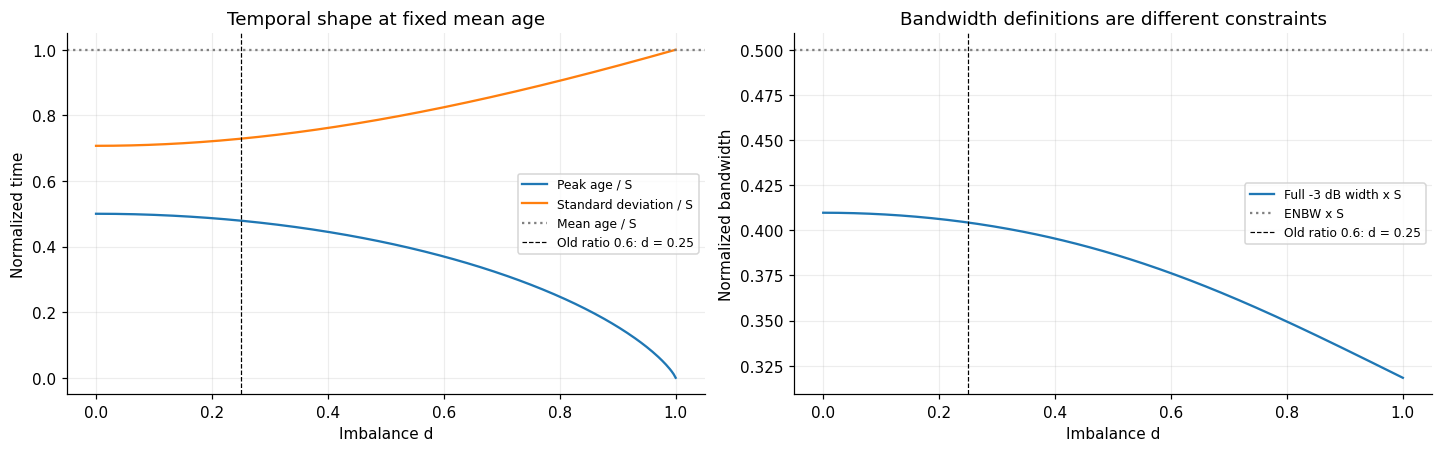

In [9]:
def shape_sweep():
    values = np.linspace(0, 1, 301)
    peak, sigma, width = np.array([continuous_shape(d) for d in values]).T
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    axes[0].plot(values, peak, label='Peak age / S')
    axes[0].plot(values, sigma, label='Standard deviation / S')
    axes[0].axhline(1, color='gray', ls=':', label='Mean age / S')
    axes[0].set(title='Temporal shape at fixed mean age', xlabel='Imbalance d', ylabel='Normalized time')
    axes[1].plot(values, width, label='Full -3 dB width x S')
    axes[1].axhline(.5, color='gray', ls=':', label='ENBW x S')
    axes[1].set(title='Bandwidth definitions are different constraints', xlabel='Imbalance d',
                ylabel='Normalized bandwidth')
    for ax in axes:
        ax.axvline(.25, color='black', lw=.8, ls='--', label='Old ratio 0.6: d = 0.25')
        ax.legend(fontsize=8)
    plt.show()
    plt.close(fig)

shape_sweep()

## Saved comparison

This ordinary output survives viewers without widgets. The default uses equal time constants;
use the slider above to compare with the single-stage endpoint or d = 0.25.

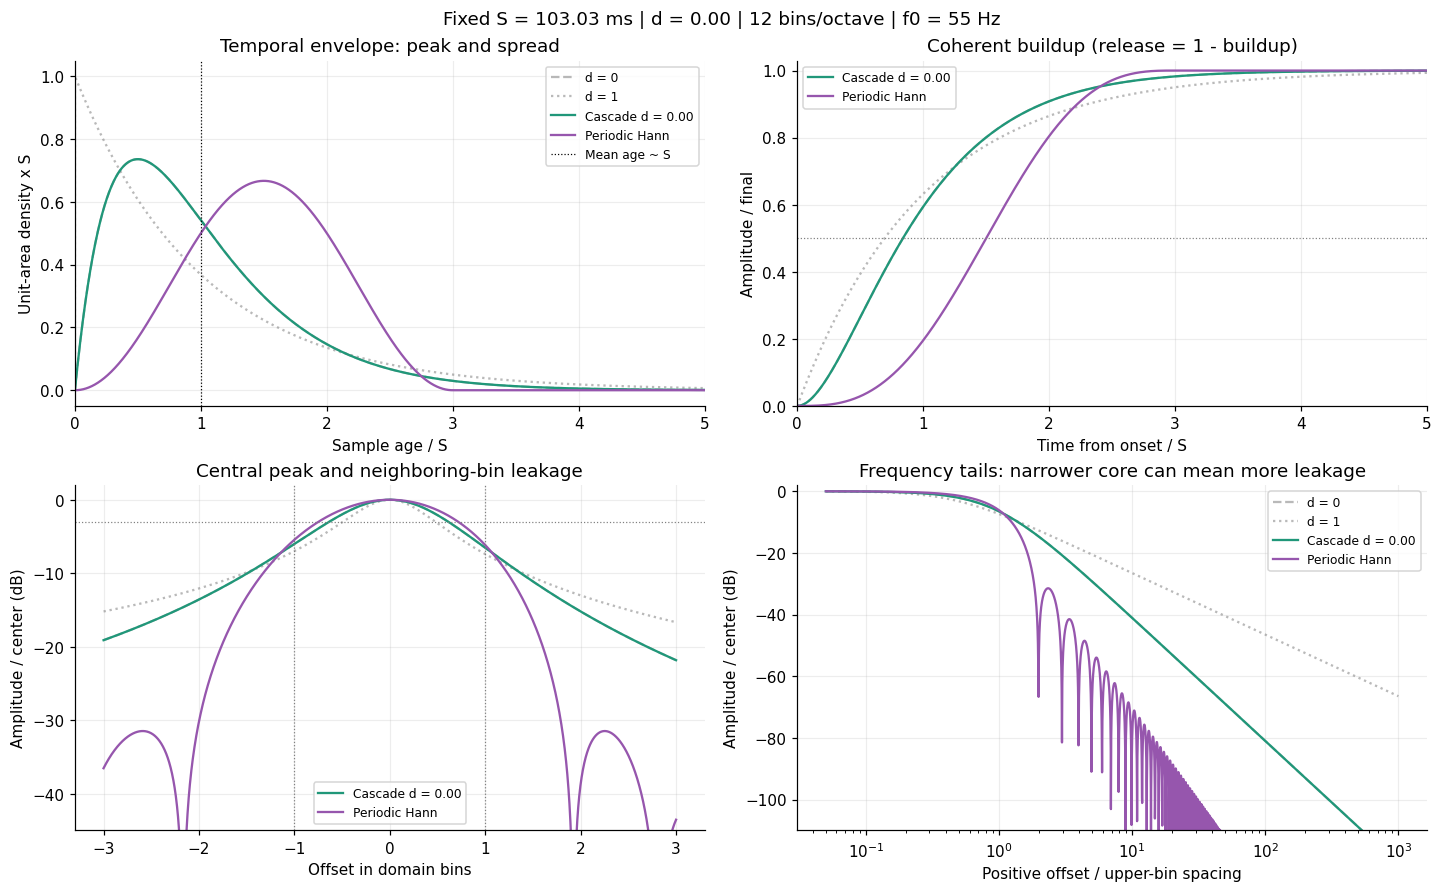

ts = 51.515 ms | tf = 51.515 ms | fast/slow = 1.0000
Hann = 14836 samples (309.083 ms), unchanged when only d moves
Continuous: peak/S = 0.5000 | mean/S = 1 | sigma/S = 0.7071
Continuous: ENBW*S = 0.5 | full -3 dB width*S = 0.4097
Exact sampled filter             mean ms    sigma ms    ENBW Hz    full -3 dB Hz
Cascade                          103.030      72.853      4.853             3.977
Hann                             154.542      55.869      4.853             4.661
Same ENBW does not imply the same mean age: Hann mean age is approximately 1.5*S.


In [10]:
shape_lab()

## Exact implementation and endpoint behavior

The stable implementation is a cascade, including one output sample of delay and a unit rotation:

```text
a = exp(-1/(fs*ts))       b = exp(-1/(fs*tf))
r = exp(i*2*pi*f0/fs)
p[n] = a*r*p[n-1] + (1-a)*x[n]
q[n] = b*r*q[n-1] + (1-b)*p[n]
y[n] = r*q[n-1]
```

At tf = 0, define b = 0: the second stage becomes the identity. Equal times need no subtraction
of nearly equal states. At d = 1 the sampled envelope still starts at age one because of the
explicit delay; the continuous limit peaks at zero. The unit rotation does not change magnitude.
The functions `responses` and `windows` evaluate complete discrete responses and stable window
weights, including both slider endpoints. Time plots crop tails; frequency responses do not.

The checks below cover the recurrence, window normalization, equal and nearly equal times,
the single-stage endpoint, swap symmetry, exact temporal moments and white-noise bandwidth.

In [11]:
def verify():
    fs = 48000
    for ts, tf in [(.05, .005), (.005, .05), (.01, .01), (.01, .010000000001), (.05, 0.), (0., .05)]:
        a, b, ca, cb = poles(fs, ts, tf)
        k = np.arange(int(np.ceil(35*max(ts, tf)*fs)))
        w = windows(k, fs, ts, tf)[-1]
        assert abs(w.sum()-1) < 1e-11
        assert w[0] == 0 and np.all(w >= 0)
        np.testing.assert_allclose(w, windows(k, fs, tf, ts)[-1], rtol=1e-10, atol=1e-14)
        assert abs(responses(0, fs, ts, tf)[2]-1) < 1e-14
        # Independent cascade recurrence at baseband, followed by a one-sample delay.
        p = q = 0.
        impulse = np.empty(len(k))
        for j in range(len(k)):
            impulse[j] = q
            p = a*p + ca*(j == 0)
            q = b*q + cb*p
        np.testing.assert_allclose(w, impulse, rtol=1e-9, atol=1e-14)
        for d in [0, 3.7, 500.3]:
            direct = np.sum(w*np.exp(-2j*np.pi*d*k/fs))
            np.testing.assert_allclose(direct, responses(d, fs, ts, tf)[2], atol=1e-11)
    for n in [4, 101, 4800]:
        k = np.arange(n)
        w = (.5-.5*np.cos(2*np.pi*k/n))/(n/2)
        for d in [0, fs/n, -fs/n, 47.3, fs/2]:
            np.testing.assert_allclose(hann_response(d, fs, n),
                np.sum(w*np.exp(-2j*np.pi*d*k/fs)), atol=2e-12)
    for d in [0., .25, .9, 1.]:
        S = .02
        ts, tf = split(S, d)
        k = np.arange(int(40*S*fs))
        w = windows(k, fs, ts, tf)[-1]
        mean, sigma, enbw, _ = sampled_metrics(fs, ts, tf)
        np.testing.assert_allclose(np.sum(k*w)/fs, mean, rtol=1e-11)
        np.testing.assert_allclose(np.sum((k/fs-mean)**2*w), sigma**2, rtol=1e-10)
        np.testing.assert_allclose(fs*np.sum(w*w), enbw, rtol=1e-11)
    print("Passed: center gain, normalization, recurrence, equal/near-equal decay, swap symmetry, and Hann response.")

verify()

Passed: center gain, normalization, recurrence, equal/near-equal decay, swap symmetry, and Hann response.


## Appendix: Hann matching and real-audio STBR observations

The main lab isolates d at fixed S and fixed Hann. This appendix retains the earlier real-audio
experiment with optional Hann matching rules. **Matching Hann -3 dB width or neighboring-bin
leakage retunes the reference when d changes**, so those modes do not isolate fixed-ENBW shape.
Use Production length for a Hann reference independent of d.

Here `S cycles = f0*S`; at every frequency the same cycle count makes S proportional to 1/f.
The default 17/3 cycles is the main lab's 12-bin/octave scale. STBR's component named S and its
frequency-slope variable d are separate quantities from the filter's time sum and imbalance.

In [12]:
def choose_hann(fs, f0, ts, tf, bins, mode, manual_cycles):
    gap = f0*(1-2**(-1/bins))  # closer, lower neighboring bin
    if mode == "Production length":
        return max(4, int(round(round(1/(2**(1/bins)-1))*fs/f0)))
    if mode == "Manual cycles":
        return max(4, int(round(manual_cycles*fs/f0)))
    if mode == "Matched bandwidth":
        bw = half_width(lambda d: responses(d, fs, ts, tf)[2], fs)
        guess = .7202912900601335*fs/bw
        candidates = {max(4, int(np.floor(guess))), max(4, int(np.ceil(guess)))}
        return min(candidates, key=lambda n: abs(half_width(lambda d: hann_response(d, fs, n), fs)-bw))
    target = abs(responses(gap, fs, ts, tf)[2])
    lo, hi = 4, max(5, int(np.ceil(2*fs/gap)))
    while hi-lo > 1:
        mid = (lo+hi)//2
        if abs(hann_response(gap, fs, mid)) > target: lo = mid
        else: hi = mid
    return min((lo, hi), key=lambda n: abs(abs(hann_response(gap, fs, n))-target))

def filter_kernels(fs, f0, slow, fast, n, count):
    k = np.arange(count)
    ts, tf = slow/f0, fast/f0
    single = windows(k, fs, ts, tf)[4]
    alpha = windows(k, fs, ts, tf)[5]
    hann = np.where(k < n, .5-.5*np.cos(2*np.pi*k/n), 0)/(n/2)
    return [single, alpha, hann]

def crossing(step, fraction, fs):
    hits = np.flatnonzero(step >= fraction)
    return hits[0]/fs if len(hits) else np.nan

## What the STBR fit actually observes

The current [`Splitter.cs`](../AEther/Splitter.cs) fits **linear magnitudes** `A = 2*abs(z)`, with
optional time slopes for S and log-frequency slopes for T. Its local sufficient statistics include:

- Per-bin temporal means, second central moments, and optional time cross-moments.
- Current frequency-neighborhood means `q` and tilts `d`.
- Temporal means and second central moments of `q` and `d`.

The second moments of neighborhood means carry cross-bin information: per-bin variances alone cannot
recover them. The Gaussian fit's residual RMS describes unexplained time/frequency interaction over
the patch. It is distinct from the signed current-cell residual and need not represent physical noise.

The following is a **direct reference projection**, rather than a port of the optimized rolling kernel.
It fits a centered two-octave patch at the selected bin (also a full-domain fit over the displayed patch).
S is plotted as the RMS of its current signed frequency field; T is the current frequency mean minus B;
R is the patch residual RMS. This matches the meanings of the production global summary.
Slopes default to the current code's settings: S time slope off, T frequency slope on.

Two time-weighting choices are available: the production finite rectangle, or an experimental common
exponential measure. The exponential has the same steady-state **mean sample age** as the rectangle,
and this choice also matches the effective sample count for independent, equally noisy observations.
Their age variances and finite support differ; actual overlapping DFT rows are correlated.
Both normalize only over available rows during startup.
Exponential weighting changes the estimator; the reference calculation retains history to show its target.
Its separable weighted moments could be updated recursively without an outgoing-row ring.

In [13]:
def project_patch(patch, time_slope=False, frequency_slope=True, weights=None):
    """Direct weighted directional projection. Rows=time, columns=log frequency."""
    a = np.asarray(patch, dtype=float)
    nt, nf = a.shape
    weights = np.ones(nt) if weights is None else np.asarray(weights, dtype=float)
    weights = weights/weights.sum()
    u = np.arange(nt, dtype=float)
    u = (u-np.dot(weights, u))/max(1, nt-1)
    x = np.linspace(-1, 1, nf) if nf > 1 else np.zeros(1)
    vu, vx = np.dot(weights, u*u), np.mean(x*x)
    m = weights@a
    q = a.mean(axis=1)
    b = m.mean()
    at = (weights*u)@a/vu if time_slope and vu > 0 else np.zeros(nf)
    d = a@x/(nf*vx) if frequency_slope and vx > 0 else np.zeros(nt)
    abar, dbar = at.mean(), np.dot(weights, d)
    c = np.mean(at*x)/vx if time_slope and frequency_slope and vx > 0 else 0.
    sf = m[None, :]-b+(at[None, :]-abar-.5*c*x[None, :])*u[:, None]
    tf = q[:, None]-b+(d[:, None]-dbar-.5*c*u[:, None])*x[None, :]
    residual = a-b-sf-tf
    rms = np.sqrt(np.sum(weights[:, None]*residual**2)/nf)
    return dict(B=b, T=q[-1]-b, S=np.sqrt(np.mean(sf[-1]**2)), R=rms,
                current_residual=residual[-1, nf//2], prediction=b+sf+tf, residual=residual)

def stbr_trace(magnitudes, rate, duration=.2, time_slope=False, frequency_slope=True,
               weighting="Finite rectangle"):
    length = max(3, int(round(duration*rate)) | 1)
    # r/(1-r) = (length-1)/2 samples: equal steady-state mean age.
    r = (length-1)/(length+1)
    result = {key: np.zeros(len(magnitudes)) for key in ["B", "T", "S", "R", "current_residual"]}
    for j in range(len(magnitudes)):
        start = max(0, j-length+1) if weighting == "Finite rectangle" else 0
        patch = magnitudes[start:j+1]
        weights = None if weighting == "Finite rectangle" else r**np.arange(len(patch)-1, -1, -1)
        fit = project_patch(patch, time_slope, frequency_slope, weights)
        for key in result: result[key][j] = fit[key]
    return result

def fft_filter_bank(audio, frequencies, fs, slow, fast, hann_mode, bins=12):
    """Offline exact causal convolution; no lookahead. No performance claim."""
    count = len(audio)
    ns = [choose_hann(fs, f, slow/f, fast/f, bins, hann_mode, 17) for f in frequencies]
    fft_size = 1 << (2*count-1).bit_length()
    spectrum = np.fft.fft(audio, fft_size)
    frames = np.arange(0, count, fs//200)  # 200 observations/second
    output = [np.empty((len(frames), len(frequencies))) for _ in range(3)]
    ages = np.arange(count)
    for j, (f, n) in enumerate(zip(frequencies, ns)):
        carrier = np.exp(2j*np.pi*f*ages/fs)
        for p, window in enumerate(filter_kernels(fs, f, slow, fast, n, count)):
            z = np.fft.ifft(spectrum*np.fft.fft(window*carrier, fft_size))[:count]
            output[p][:, j] = 2*np.abs(z[frames])
    return frames/fs, output

def audio_experiment(f0=55., S_cycles=17/3, d=0., scenario="Tone plus noise burst", neighbor_db=0.,
                     phase=0., cents=0., hann_mode="Production length", fit_ms=200.,
                     time_slope=False, frequency_slope=True, weighting="Finite rectangle"):
    slow, fast = split(S_cycles, d)
    fs, stop, rate = 8000, 2.5, 200
    t = np.arange(int(fs*stop))/fs
    frequencies = f0*2**(np.arange(-12, 13)/12)
    rng = np.random.default_rng(417)
    on, off = .3, 1.25
    gate = ((t >= on) & (t < off)).astype(float)
    f = f0*2**(cents/1200)
    base = np.cos(2*np.pi*f*t+phase)*gate
    boundaries = [on, off]
    if scenario == "Tone plus noise burst":
        burst = ((t >= .65) & (t < .73)).astype(float)
        audio = .3*base+.3*rng.standard_normal(len(t))*burst
        boundaries += [.65, .73]
    elif scenario == "Neighbor overlaps":
        other = ((t >= .65) & (t < 1.6)).astype(float)
        audio = .3*(base+10**(neighbor_db/20)*np.cos(2*np.pi*f*2**(1/12)*t+phase+1.1)*other)
        boundaries += [.65, 1.6]
    elif scenario == "Neighbor replaces tone":
        switch = .8
        audio = .3*np.where(t < switch, np.cos(2*np.pi*f*t+phase),
                            10**(neighbor_db/20)*np.cos(2*np.pi*f*2**(1/12)*t+phase+1.1))*gate
        boundaries += [switch]
    elif scenario == "Synchronous bin tones":
        # Deterministic phases and simultaneous gates; all frequencies start together.
        ph = rng.uniform(-np.pi, np.pi, len(frequencies))
        audio = .3*np.cos(2*np.pi*t[:, None]*frequencies[None, :]+ph).sum(axis=1)/np.sqrt(len(frequencies))*gate
    else:
        audio = .3*rng.standard_normal(len(t))*gate
    times, banks = fft_filter_bank(audio, frequencies, fs, slow, fast, hann_mode)
    fits = [stbr_trace(a, rate, fit_ms/1000, time_slope, frequency_slope, weighting) for a in banks]
    names = ["Fast exponential", "Two-pole cascade", "Periodic Hann"]
    peak = max(np.max(a) for a in banks)
    fig, axes = plt.subplots(3, 3, figsize=(15, 9), constrained_layout=True, sharex=True)
    for col, (name, a, fit) in enumerate(zip(names, banks, fits)):
        im = axes[0, col].pcolormesh(times, np.arange(-12, 13), db(a/max(peak, 1e-15)).T,
                                    shading="auto", vmin=-60, vmax=0, cmap="magma")
        axes[0, col].set(title=name, ylabel="Semitones from center")
        axes[1, col].plot(times, fit["T"], label="T · signed current mean − B", color=COLORS["fast"])
        axes[1, col].plot(times, fit["B"], label="B · patch mean", color="gray")
        axes[1, col].axhline(0, color="gray", lw=.7)
        axes[1, col].set(ylabel="Linear amplitude", title="Temporal effect and background")
        axes[2, col].plot(times, fit["S"], label="S · current field RMS", color=COLORS["slow"])
        axes[2, col].plot(times, fit["R"], label="R · patch residual RMS", color=COLORS["alpha"])
        axes[2, col].set(xlabel="Time (s)", ylabel="Linear amplitude", title="Structure and interaction")
        for row in [1, 2]: axes[row, col].legend(fontsize=8)
        for row in range(3):
            for edge in boundaries: axes[row, col].axvline(edge, color="gray", lw=.7, ls=":")
    # Share amplitude limits across paths, retaining the negative T range.
    for row in [1, 2]:
        low = min(ax.get_ylim()[0] for ax in axes[row]); high = max(ax.get_ylim()[1] for ax in axes[row])
        for ax in axes[row]: ax.set_ylim(low, high)
    fig.colorbar(im, ax=axes[0, :], label="Magnitude (dB / common peak)", shrink=.75)
    fig.suptitle(f"{scenario} · S={S_cycles:.2f} cycles · d={d:.2f} · center {f0:g} Hz · {weighting}")
    plt.show(); plt.close(fig)
    fig, ax = plt.subplots(figsize=(13, 1.6), constrained_layout=True)
    ax.plot(t[::8], audio[::8], color="gray", lw=.5)
    ax.set(xlabel="Time (s)", ylabel="Input", title="Generated waveform (display decimated)")
    plt.show(); plt.close(fig)
    print("All paths share the input, fit settings, plot limits and coherent gain. Noise gains differ.")
    print("Frequency-dependent decay also changes how synchronized events line up across bins.")
    print("A rise in R can describe filter-induced spectral evolution; it does not by itself identify noise.")
    print("This is one centered patch, not the full collection of overlapping local production fits.")

audio_controls = {
    "f0": W.Dropdown(options=[40., 55., 110., 220., 440.], value=55., description="Center Hz"),
    "S_cycles": W.FloatSlider(value=17/3, min=1, max=24, step=1/3, description="S cycles", continuous_update=False),
    "d": W.FloatSlider(value=0, min=0, max=1, step=.01, description="Imbalance d", continuous_update=False),
    "scenario": W.Dropdown(options=["Tone plus noise burst", "Neighbor overlaps", "Neighbor replaces tone", "Synchronous bin tones", "Noise burst"],
                           description="Input", layout=W.Layout(width="420px")),
    "neighbor_db": W.FloatSlider(value=0, min=-20, max=20, step=2, description="Neighbor dB", continuous_update=False),
    "phase": W.FloatSlider(value=0, min=-np.pi, max=np.pi, step=.2, description="Phase rad", continuous_update=False),
    "cents": W.FloatSlider(value=0, min=-50, max=50, step=5, description="Detune cents", continuous_update=False),
    "hann_mode": W.Dropdown(options=["Matched neighboring note", "Matched bandwidth", "Production length"],
                            value="Production length", description="Hann match", layout=W.Layout(width="420px")),
    "fit_ms": W.FloatSlider(value=200, min=20, max=500, step=20, description="Fit ms", continuous_update=False),
    "time_slope": W.Checkbox(value=False, description="S time slope"),
    "frequency_slope": W.Checkbox(value=True, description="T frequency slope"),
    "weighting": W.Dropdown(options=["Finite rectangle", "Exponential (equal mean age)"], description="Fit weights",
                           layout=W.Layout(width="420px")),
}
audio_output = W.interactive_output(audio_experiment, audio_controls)
display(W.VBox([W.HBox([audio_controls["scenario"], audio_controls["f0"]]),
                W.HBox([audio_controls["S_cycles"], audio_controls["d"]]),
                W.HBox([audio_controls["neighbor_db"], audio_controls["cents"], audio_controls["phase"]]),
                W.HBox([audio_controls["hann_mode"], audio_controls["fit_ms"]]),
                W.HBox([audio_controls["weighting"], audio_controls["time_slope"], audio_controls["frequency_slope"]])]), audio_output)

Output()

## Can the transform and splitter be fused?

**Implementation fusion is plausible. Statistical equivalence needs an explicit observation model.**
The current path is `waveform → complex filtered values z → magnitudes A → directional fit`.
The magnitude is nonlinear: `abs(mean(z)) != mean(abs(z))`. Resonator states alone cannot replace
the temporal magnitude means and second moments used by today's fit. Likewise, changing from
magnitude to power changes both units and the fitted decomposition.

For an exponential time measure shared by all bins in a patch, candidate streaming state is:

```text
A[f] = 2*abs(z[f])
q = mean_frequency(A)
d = frequency slope of A

E[A[f]], E[A[f]^2], optional E[age*A[f]]
E[q], E[q^2], E[d], E[d^2], optional E[age*q], E[age*d]
```

The common measure makes the time/frequency projections compatible and permits recursive updates.
Finite rectangular support instead requires enough information to remove outgoing observations.
No buffer-free reformulation of that exact support is demonstrated here. A positive age PDF for
the transform also does not make the STBR scores classification probabilities.

The difficult design choice is **which observations define one STBR fit**. Feeding fast magnitudes to T/R
and selective magnitudes to S/B generally loses the identity that all four describe the same magnitude
patch. A useful next experiment would define a joint model with separate measurement operators and
their delays, then examine its residual. Calling the difference between a fast and slow spectrum R
would assign filter mismatch to the residual without such a model.

Frequency-scaled windows compound this issue: simultaneous input changes arrive at different effective
ages across bins. Delaying fast bins can align them by adding latency. Alternatives include common short
windows for broad transient observations, selective windows for sustained observations, and a joint model
that accounts for both. The existing Analyzer already publishes a waveform transient event before the DFT;
that event is separate from the spectral T and residual statistics studied here.

Questions the plots should help decide:

1. Does the intended R describe unresolved spectral interaction, physical noise, or a fast rendering control?
2. Can T/R and S/B have different observation meanings, or must they retain one joint reconstruction model?
3. How much unequal-neighbor leakage is acceptable during the first 20–50 ms of a bass attack?

Production use also needs an explicit silence/reset policy: exponential states decay indefinitely rather
than expiring after a finite sample ring.

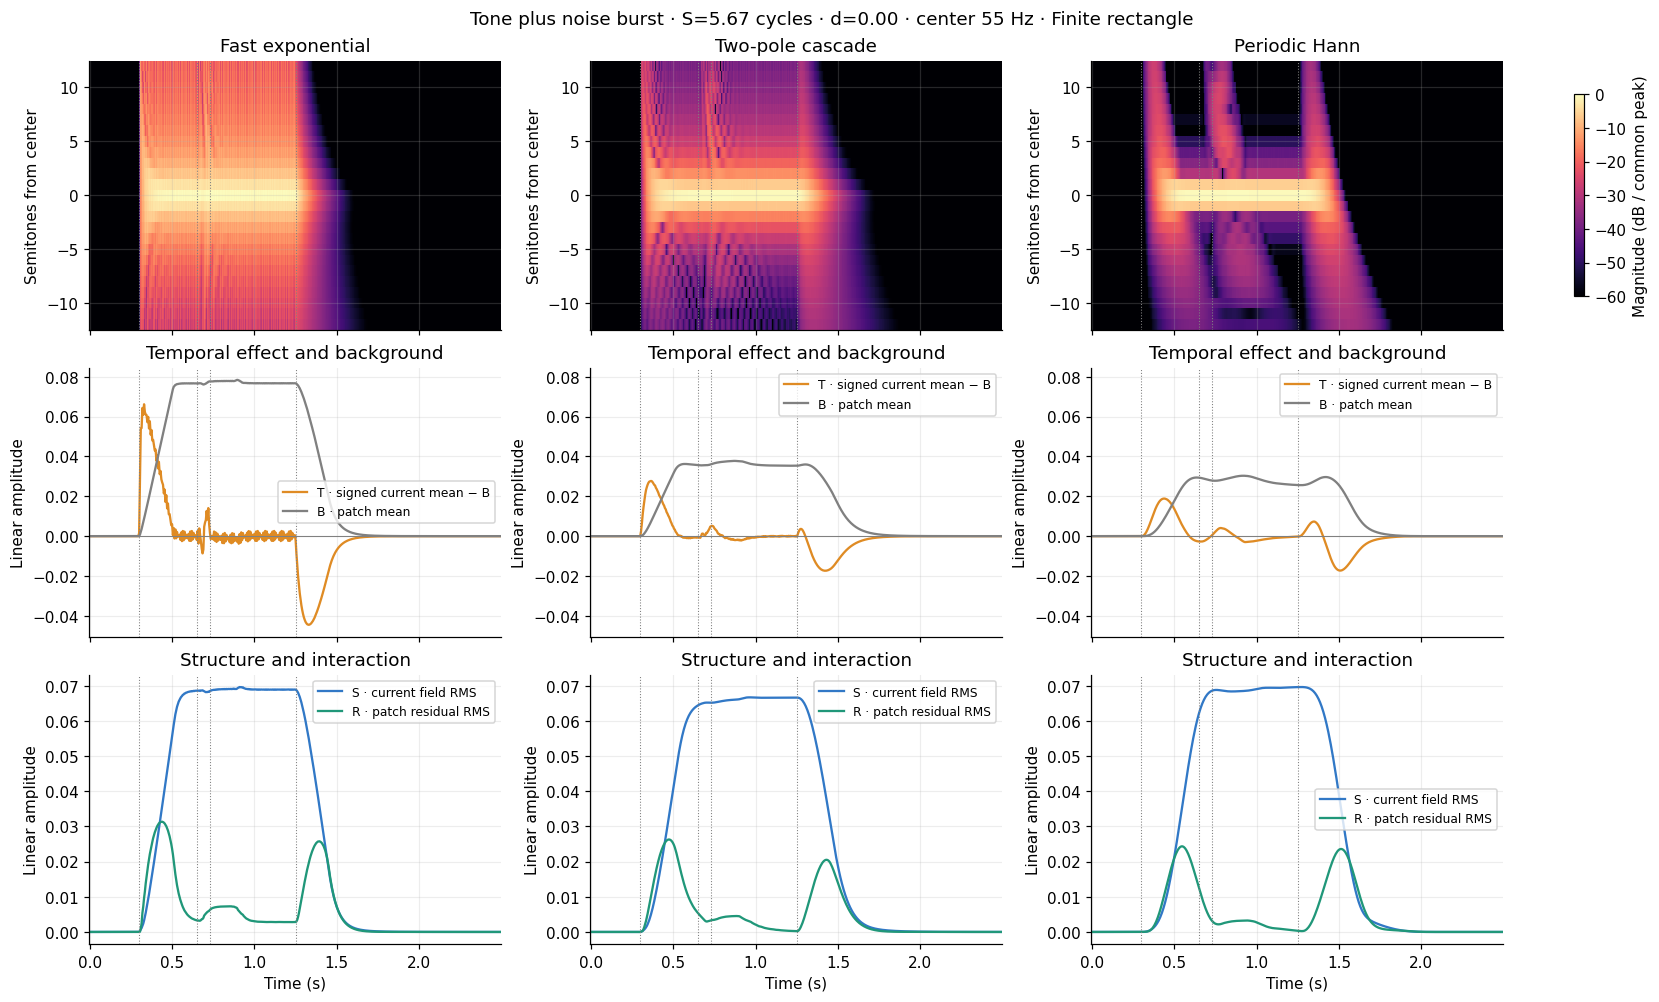

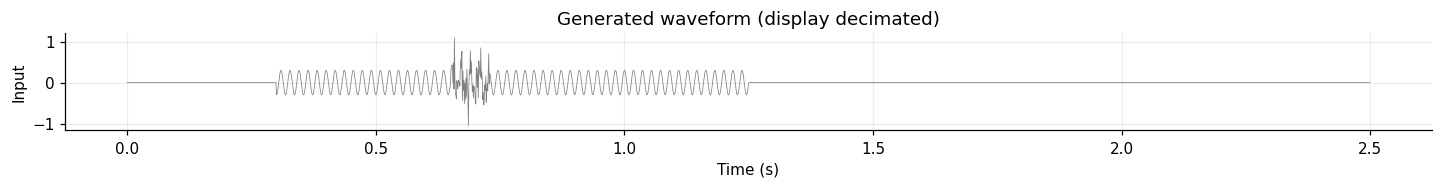

All paths share the input, fit settings, plot limits and coherent gain. Noise gains differ.
Frequency-dependent decay also changes how synchronized events line up across bins.
A rise in R can describe filter-induced spectral evolution; it does not by itself identify noise.
This is one centered patch, not the full collection of overlapping local production fits.


In [14]:
audio_experiment()

### Appendix numerical checks

Retain the independent Hann matching, weighted least-squares, causal convolution and STBR checks.
These validate the experiment machinery; they do not establish an optimal default or production replacement.

In [15]:
def verify_extension():
    fs, f0, slow, fast = 8000, 55., 5., 3.
    ts, tf = slow/f0, fast/f0
    n = choose_hann(fs, f0, ts, tf, 12, "Matched neighboring note", 17)
    gap = f0*(1-2**(-1/12))
    target = abs(responses(gap, fs, ts, tf)[2])
    error = abs(abs(hann_response(gap, fs, n))-target)
    assert all(error <= abs(abs(hann_response(gap, fs, j))-target)+1e-14 for j in [n-1, n+1])
    assert choose_hann(fs, f0, ts, tf, 12, "Production length", 17) == round(17*fs/f0)
    rng = np.random.default_rng(81)
    a = rng.uniform(0, 1, (9, 7))
    for slope_t in [False, True]:
        for slope_f in [False, True]:
            for weights in [np.ones(9), .8**np.arange(8, -1, -1)]:
                fit = project_patch(a, slope_t, slope_f, weights)
                # Independent full design: time profiles per bin and frequency profiles per row.
                t, x = np.meshgrid(np.arange(9), np.linspace(-1, 1, 7), indexing="ij")
                design = [np.ones(a.size)]
                for j in range(7):
                    column = np.broadcast_to(np.arange(7) == j, a.shape)
                    design.append(column.ravel())
                    if slope_t: design.append((column*t).ravel())
                for j in range(9):
                    row = np.broadcast_to((np.arange(9) == j)[:, None], a.shape)
                    design.append(row.ravel())
                    if slope_f: design.append((row*x).ravel())
                design = np.array(design).T
                root = np.sqrt(np.repeat(weights/weights.sum(), 7))
                beta = np.linalg.lstsq(design*root[:, None], a.ravel()*root, rcond=None)[0]
                np.testing.assert_allclose(fit["prediction"], (design@beta).reshape(a.shape), atol=2e-13)
                direct_rms = np.sqrt(np.sum(weights[:, None]*fit["residual"]**2)/(weights.sum()*7))
                np.testing.assert_allclose(fit["R"], direct_rms, atol=1e-14)
    flat = project_patch(a, False, False)
    np.testing.assert_allclose(flat["R"]**2,
                               np.var(a, axis=0).mean()-np.var(a.mean(axis=1)), atol=1e-14)
    for nt, nf in [(1, 7), (9, 1), (2, 7), (9, 2)]:
        z = rng.random((nt, nf))
        np.testing.assert_allclose(project_patch(z, True, True)["R"], 0, atol=2e-13)
    # Infinite-window noise gain, including the equal-pole limit.
    for s, f in [(5., 3.), (3., 3.), (3., 5.)]:
        a0, b0, ca0, cb0 = poles(fs, s/f0, f/f0)
        norm = ca0*cb0*(1+a0*b0)/((1+a0)*(1+b0)*(-np.expm1(-f0/(fs*s)-f0/(fs*f))))
        w = windows(np.arange(int(20*max(s, f)*fs/f0)), fs, s/f0, f/f0)[-1]
        np.testing.assert_allclose(np.sum(w*w), norm, rtol=2e-12)
    # Equal-mean-age EMA and rectangle also have equal white-observation effective counts.
    length = 41
    r = (length-1)/(length+1)
    np.testing.assert_allclose(r/(1-r), (length-1)/2)
    np.testing.assert_allclose((1+r)/(1-r), length)
    # Real input, FFT implementation, several actual frame times and all three filters.
    audio = rng.normal(size=400)
    times, bank = fft_filter_bank(audio, [55.], fs, slow, fast, "Production length")
    n = choose_hann(fs, f0, ts, tf, 12, "Production length", 17)
    kernels = filter_kernels(fs, f0, slow, fast, n, len(audio))
    carrier = np.exp(2j*np.pi*f0*np.arange(len(audio))/fs)
    for p, w in enumerate(kernels):
        direct = np.convolve(audio, w*carrier)[:len(audio)]
        np.testing.assert_allclose(bank[p][:, 0], 2*np.abs(direct[(times*fs).round().astype(int)]), atol=2e-14)
    # A flat time-frequency field has B only, including weighted startup.
    for mode in ["Finite rectangle", "Exponential (equal mean age)"]:
        trace = stbr_trace(np.ones((80, 7)), 200, weighting=mode)
        np.testing.assert_allclose(trace["B"], 1, atol=1e-14)
        for key in ["S", "T", "R"]: np.testing.assert_allclose(trace[key], 0, atol=1e-13)
    print("Passed: neighboring-note match, production length, weighted projection vs least squares,")
    print("flat ANOVA residual, degenerate supports, noise gains, EMA age/count, causal FFT convolution, and weighted startup.")

verify_extension()

Passed: neighboring-note match, production length, weighted projection vs least squares,
flat ANOVA residual, degenerate supports, noise gains, EMA age/count, causal FFT convolution, and weighted startup.


## References and scope

- [Production SWIFT tuning](../AEther/DFT/SwiftTuning.cs): full -3 dB width relative to geometric
  bin width, with width scale 1 and imbalance 0 by default. The whole-bank lab uses this rule;
  the separate fixed-S/Hann-ENBW comparison illustrates shape without retuning S.
- [Production cascade](../AEther/DFT/SwiftProcessor.cs): two complex states and delayed output.
- [Constant-Q transform](https://en.wikipedia.org/wiki/Constant-Q_transform): logarithmic centers
  and bandwidth proportional to center frequency. A numerical Q requires a bandwidth definition.
- [Cornell SWIFT implementation](https://people.ece.cornell.edu/land/courses/ece4760/RP2350/SWIFT/index_swift.html).

The scale/spread formulas are continuous-time results. Exact sampled response, moments and ENBW
are computed alongside them. At very short times they need not coincide. Matching Hann's ENBW
matches white-noise output power at equal coherent gain, not the entire frequency response,
mean noise magnitude, temporal latency, or ability to separate unequal real tones.